Homework 3, problem 2, part c

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import root_scalar

In [2]:
# parameters
tau = 1.0
v_r = 0.0
v_th = 1.0
I_lif = 1.5
delta = 1e-3

# analytical period delta
Delta_lif = tau * np.log((I_lif * tau - v_r) / (I_lif * tau - v_th))

def lif_analytical_prc(phi):
    return (tau * np.exp(phi * Delta_lif / tau)) / (Delta_lif * (I_lif * tau - v_r))

def lif_numerical_prc(phi):
    t_kick = phi * Delta_lif
    v_at_kick = I_lif * tau * (1 - np.exp(-t_kick / tau))
    
    v_after_kick = v_at_kick + delta
    if v_after_kick >= v_th:
        return (Delta_lif - t_kick) / (Delta_lif * delta)
    
    t_rem = -tau * np.log((I_lif * tau - v_th) / (I_lif * tau - v_after_kick))
    
    T_prime = t_kick + t_rem
    return (Delta_lif - T_prime) / (Delta_lif * delta)

phi_grid = np.linspace(0, 1, 100)
prc_lif_num = [lif_numerical_prc(p) for p in phi_grid]
prc_lif_ana = lif_analytical_prc(phi_grid)

In [3]:
def fhn_derivs(t, y):
    v, w = y
    dv = v - (v**3)/3 - w + 0.5
    dw = 0.08 * (v + 0.7 - 0.8 * w)
    return [dv, dw]

def v_zero_crossing(t, y):
    return y[0]
v_zero_crossing.direction = 1

sol_relax = solve_ivp(fhn_derivs, [0, 200], [1.0, 1.0], rtol=1e-10, atol=1e-10)
y_init = sol_relax.y[:, -1]

sol_period = solve_ivp(fhn_derivs, [0, 100], y_init, events=v_zero_crossing, rtol=1e-11, atol=1e-11)
t_crossings = sol_period.t_events[0]
Delta_fhn = t_crossings[1] - t_crossings[0]
y_start = sol_period.y_events[0][0]

print(f"LIF Period (Delta): {Delta_lif:.5f}")
print(f"FHN Period (Delta): {Delta_fhn:.5f}")

def fhn_numerical_prc(phi, num_cycles=4):
    t_kick = phi * Delta_fhn
    
    sol1 = solve_ivp(fhn_derivs, [0, t_kick], y_start, rtol=1e-11, atol=1e-11)
    y_at_kick = sol1.y[:, -1]
    
    y_after_kick = [y_at_kick[0] + delta, y_at_kick[1]]
    
    t_max = (num_cycles + 2) * Delta_fhn
    sol2 = solve_ivp(fhn_derivs, [t_kick, t_max], y_after_kick, events=v_zero_crossing, rtol=1e-11, atol=1e-11)
    
    t_perturbed_crossing = sol2.t_events[0][num_cycles - 1]
    t_unperturbed_crossing = num_cycles * Delta_fhn
    
    return (t_unperturbed_crossing - t_perturbed_crossing) / (Delta_fhn * delta)

phi_grid_fhn = np.linspace(0, 1, 50)
prc_fhn_num = [fhn_numerical_prc(p) for p in phi_grid_fhn]

LIF Period (Delta): 1.09861
FHN Period (Delta): 39.47441


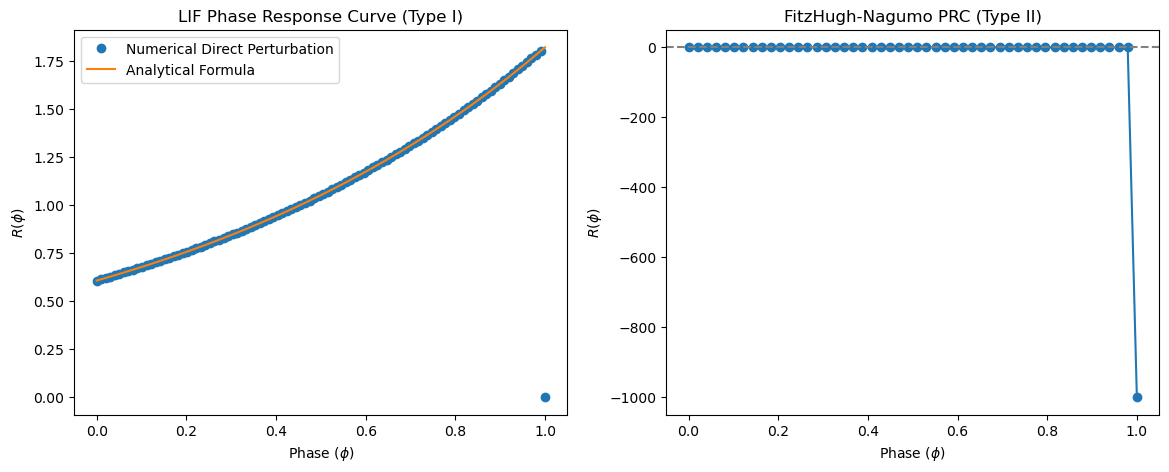

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# LIF
axes[0].plot(phi_grid, prc_lif_num, 'o', label='Numerical Direct Perturbation')
axes[0].plot(phi_grid, prc_lif_ana, '-', label='Analytical Formula')
axes[0].set_title('LIF Phase Response Curve (Type I)')
axes[0].set_xlabel('Phase ($\phi$)')
axes[0].set_ylabel('$R(\phi)$')
axes[0].legend()

# FHN
axes[1].plot(phi_grid_fhn, prc_fhn_num, '-o')
axes[1].axhline(0, color='gray', linestyle='--')
axes[1].set_title('FitzHugh-Nagumo PRC (Type II)')
axes[1].set_xlabel('Phase ($\phi$)')
axes[1].set_ylabel('$R(\phi)$')

plt.show()
